<a href="https://colab.research.google.com/github/abhijithvalluri7-creator/Ecommerce-Sales-Analysis/blob/main/Day01_Ecommerce_Sales_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

df = pd.read_excel('/content/Online Retail.xlsx')

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
df.info()

Dataset Shape: (541909, 8)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data Types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [3]:
print("Missing Values by Column:")
print(df.isnull().sum())

print("\nMissing Percentage:")
print((df.isnull().sum() / len(df) * 100).round(2))

Missing Values by Column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Missing Percentage:
InvoiceNo       0.00
StockCode       0.00
Description     0.27
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
CustomerID     24.93
Country         0.00
dtype: float64


In [4]:
print("Total Rows:", len(df))

print("Exact Duplicate Rows:", df.duplicated().sum())

print("Unique Invoice Numbers:", df["InvoiceNo"].nunique())

print("Cancelled Invoice Lines:",
      df["InvoiceNo"].astype(str).str.startswith("C").sum())

print("Negative Quantity Rows:",
      (df["Quantity"] < 0).sum())

print("Zero or Negative Price Rows:",
      (df["UnitPrice"] <= 0).sum())

Total Rows: 541909
Exact Duplicate Rows: 5268
Unique Invoice Numbers: 25900
Cancelled Invoice Lines: 9288
Negative Quantity Rows: 10624
Zero or Negative Price Rows: 2517


In [5]:
# Preserve the original dataset
raw = df.copy()

# Create a separate working dataset
clean = raw.copy()

# Remove exact duplicate rows
clean = clean.drop_duplicates()

# Remove rows without product descriptions
clean = clean.dropna(subset=["Description"])

# Keep only positive quantities
clean = clean[clean["Quantity"] > 0]

# Keep only positive prices
clean = clean[clean["UnitPrice"] > 0]

# Exclude cancellation invoices
clean = clean[
    ~clean["InvoiceNo"].astype(str).str.startswith("C")
]

# Display results
print("Original Rows:", len(raw))
print("Cleaned Rows:", len(clean))
print("Excluded Rows:", len(raw) - len(clean))

clean.head()

Original Rows: 541909
Cleaned Rows: 524878
Excluded Rows: 17031


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
# Calculate revenue for every sales line
clean["Revenue"] = clean["Quantity"] * clean["UnitPrice"]

# Display first 5 rows with the new Revenue column
clean[["InvoiceNo", "Quantity", "UnitPrice", "Revenue"]].head()

,InvoiceNo,Quantity,UnitPrice,Revenue
0,536365,6,2.55,15.30
1,536365,6,3.39,20.34
2,536365,8,2.75,22.00
3,536365,6,3.39,20.34
4,536365,6,3.39,20.34


In [7]:
# Total revenue from positive sales
total_revenue = clean["Revenue"].sum()

# Number of unique invoices
total_orders = clean["InvoiceNo"].nunique()

# Number of identified customers
total_customers = clean["CustomerID"].nunique()

# Total units sold
total_units = clean["Quantity"].sum()

# Average revenue per order
average_order_value = total_revenue / total_orders

# Display results
print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Identified Customers: {total_customers:,}")
print(f"Total Units Sold: {total_units:,}")
print(f"Average Order Value: £{average_order_value:,.2f}")

Total Revenue: £10,642,110.80
Total Orders: 19,960
Identified Customers: 4,338
Total Units Sold: 5,572,420
Average Order Value: £533.17


In [8]:
# Group revenue by country
country_sales = (
    clean.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Display top 10 countries
print("Top 10 Countries by Revenue:")
print(country_sales.head(10))

Top 10 Countries by Revenue:
Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64


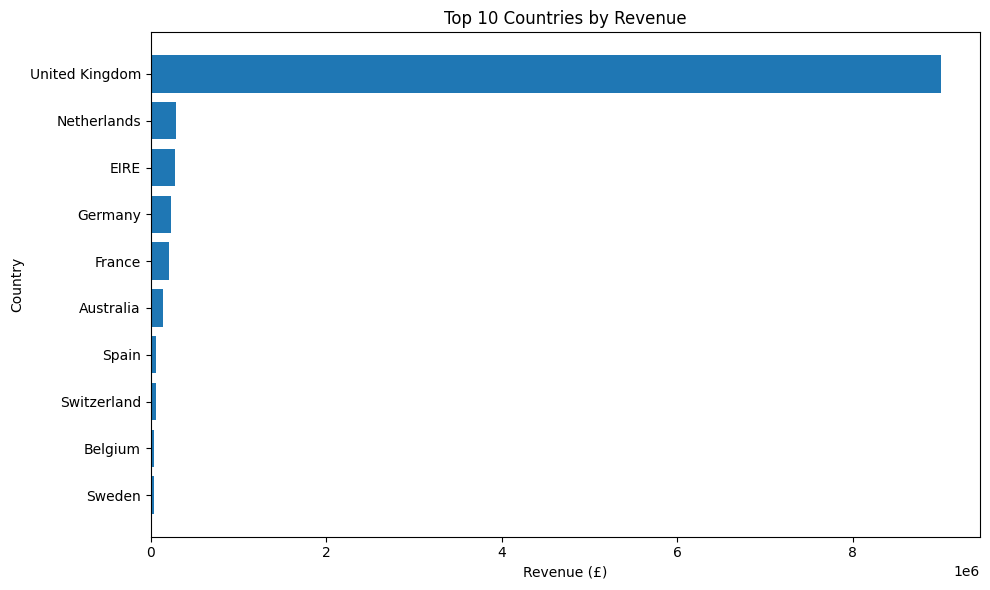

In [9]:
import matplotlib.pyplot as plt

# Select the top 10 countries
top10 = country_sales.head(10)

# Create chart
plt.figure(figsize=(10, 6))

plt.barh(
    top10.index[::-1],
    top10.values[::-1]
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

In [10]:
# Calculate total revenue by product
product_sales = (
    clean.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Display top 10 products
print("Top 10 Products by Revenue:")
print(product_sales.head(10))

Top 10 Products by Revenue:
Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Revenue, dtype: float64


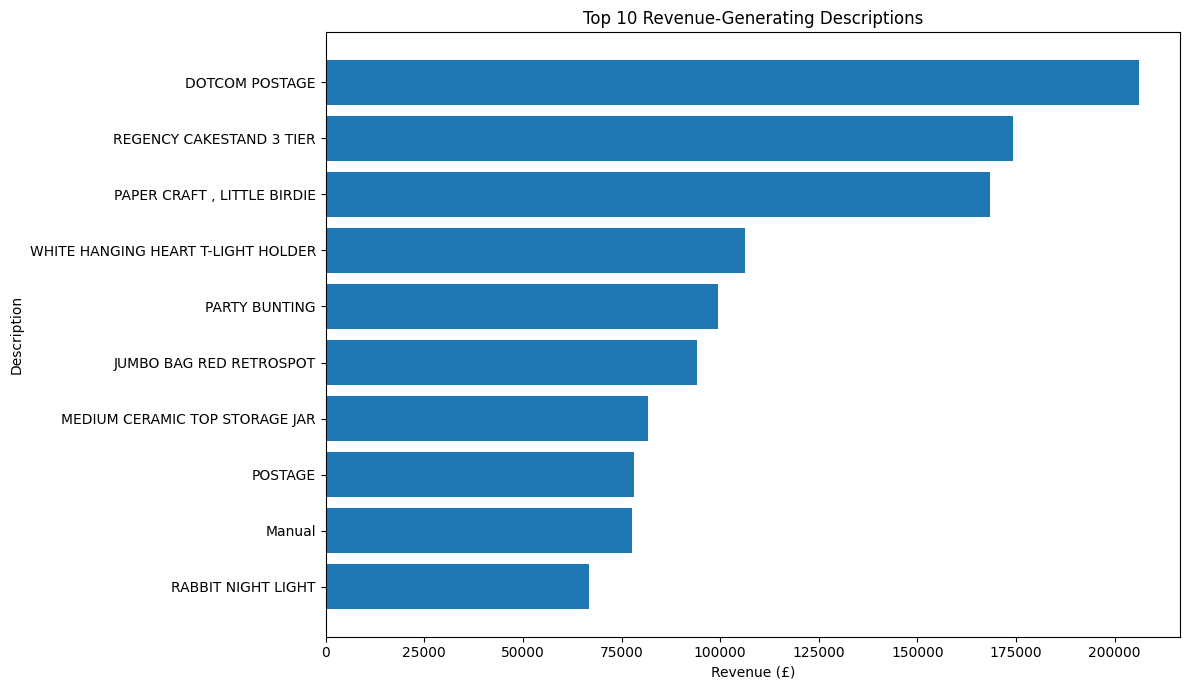

In [11]:
# Select top 10 descriptions by revenue
top_products = product_sales.head(10)

# Create chart
plt.figure(figsize=(12, 7))

plt.barh(
    top_products.index[::-1],
    top_products.values[::-1]
)

plt.title("Top 10 Revenue-Generating Descriptions")
plt.xlabel("Revenue (£)")
plt.ylabel("Description")

plt.tight_layout()
plt.show()

In [12]:
# Identify possible non-product charges
special_items = clean[
    clean["Description"].str.contains(
        "POSTAGE|MANUAL|CARRIAGE|BANK CHARGES|DISCOUNT",
        case=False,
        na=False
    )
]

# Display their revenue
print("Potential Non-Product Transactions:")

print(
    special_items.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(20)
)

Potential Non-Product Transactions:
Description
DOTCOM POSTAGE                  206248.770
POSTAGE                          78101.880
Manual                           77752.820
CARRIAGE                          7051.000
Next Day Carriage                 1200.000
FRENCH CARRIAGE LANTERN            925.350
BLACK BAROQUE CARRIAGE CLOCK       432.790
Bank Charges                       165.001
Name: Revenue, dtype: float64


In [13]:
# Explicitly identified non-merchandise descriptions
non_product_descriptions = [
    "DOTCOM POSTAGE",
    "POSTAGE",
    "Manual",
    "CARRIAGE",
    "Next Day Carriage",
    "Bank Charges"
]

# Create merchandise-only dataset
products_only = clean[
    ~clean["Description"].isin(non_product_descriptions)
].copy()

# Calculate product revenue
product_only_sales = (
    products_only.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Merchandise Descriptions:")
print(product_only_sales.head(10))

Top 10 Merchandise Descriptions:
Description
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
RABBIT NIGHT LIGHT                     66870.03
PAPER CHAIN KIT 50'S CHRISTMAS         64875.59
ASSORTED COLOUR BIRD ORNAMENT          58927.62
CHILLI LIGHTS                          54096.36
Name: Revenue, dtype: float64


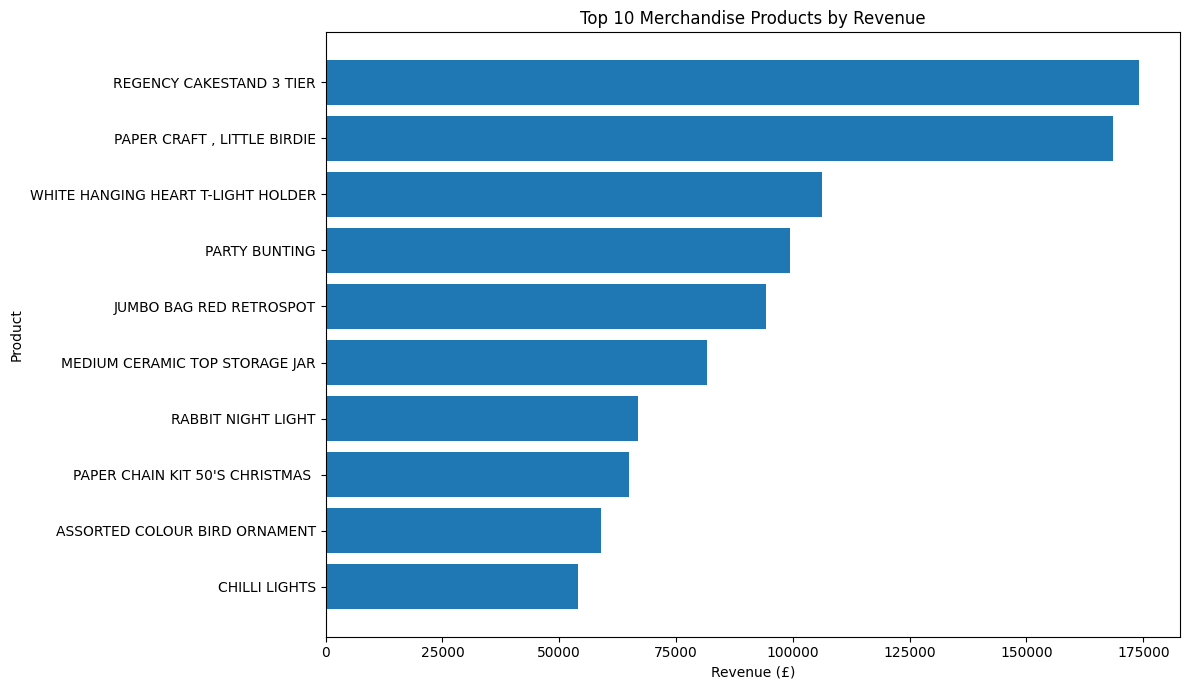

In [14]:
# Select top 10 merchandise descriptions
top_merchandise = product_only_sales.head(10)

# Create horizontal bar chart
plt.figure(figsize=(12, 7))

plt.barh(
    top_merchandise.index[::-1],
    top_merchandise.values[::-1]
)

plt.title("Top 10 Merchandise Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [15]:
# Ensure invoice dates are in datetime format
clean["InvoiceDate"] = pd.to_datetime(clean["InvoiceDate"])

# Extract year and month
clean["Month"] = clean["InvoiceDate"].dt.to_period("M")

# Calculate monthly revenue
monthly_sales = (
    clean.groupby("Month")["Revenue"]
    .sum()
    .sort_index()
)

print("Monthly Revenue:")
print(monthly_sales)

Monthly Revenue:
Month
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Freq: M, Name: Revenue, dtype: float64


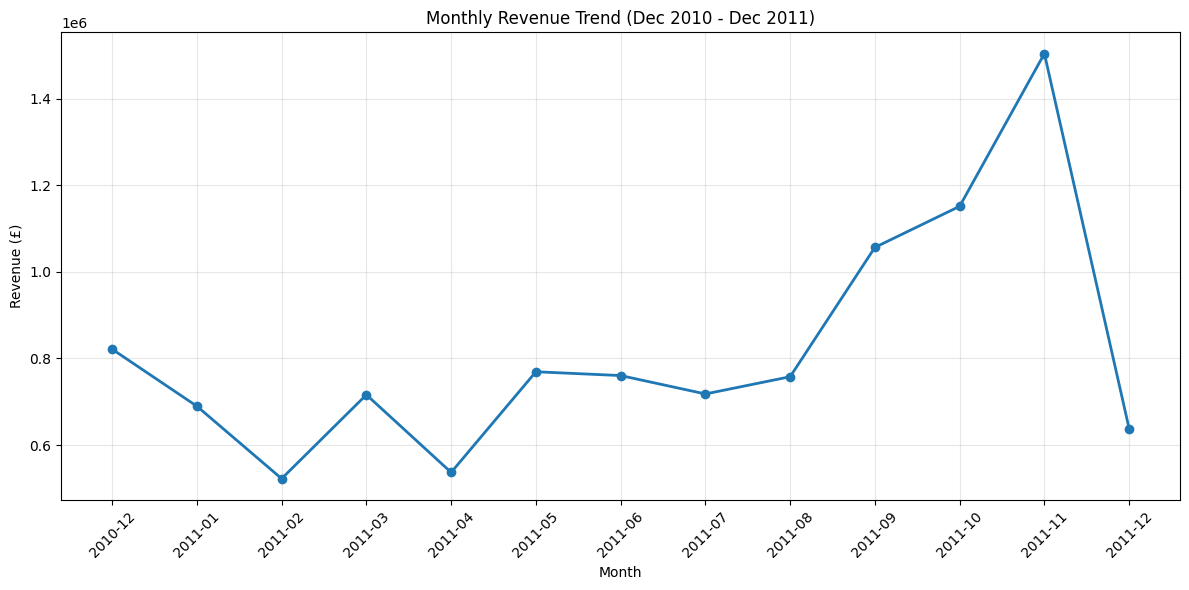

In [16]:
# Create monthly revenue line chart
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Revenue Trend (Dec 2010 - Dec 2011)")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [17]:
# Identify cancelled invoice lines
cancelled = df[
    df["InvoiceNo"].astype(str).str.startswith("C")
].copy()

# Calculate cancellation statistics
cancelled_invoices = cancelled["InvoiceNo"].nunique()
cancelled_lines = len(cancelled)

# Calculate value of negative quantity lines
cancelled["ReturnValue"] = (
    cancelled["Quantity"] * cancelled["UnitPrice"]
)

total_cancelled_value = -cancelled.loc[
    cancelled["ReturnValue"] < 0, "ReturnValue"
].sum()

print("Cancelled Invoice Analysis")
print("--------------------------")
print("Unique Cancelled Invoices:", cancelled_invoices)
print("Cancelled Invoice Lines:", cancelled_lines)
print(f"Value of Negative Cancellation Lines: £{total_cancelled_value:,.2f}")

Cancelled Invoice Analysis
--------------------------
Unique Cancelled Invoices: 3836
Cancelled Invoice Lines: 9288
Value of Negative Cancellation Lines: £896,812.49


In [18]:
# Count total unique invoices
total_invoices = df["InvoiceNo"].nunique()

# Calculate cancellation rate
cancellation_rate = (
    cancelled_invoices / total_invoices
) * 100

# Display results
print("Total Unique Invoices:", total_invoices)
print("Cancelled Invoices:", cancelled_invoices)
print(f"Cancellation Rate: {cancellation_rate:.2f}%")

Total Unique Invoices: 25900
Cancelled Invoices: 3836
Cancellation Rate: 14.81%


## Business Insights and Recommendations

After cleaning and analyzing the Online Retail dataset, I identified a few interesting patterns in sales performance, product demand, and cancellations.

### Key Findings

**1. Sales are heavily concentrated in the UK**

The UK accounts for approximately 84.6% of total positive-sales revenue. While this shows a strong domestic customer base, it also suggests that the business depends heavily on one market.

**2. Certain products contribute significantly to revenue**

Regency Cakestand 3 Tier was the highest revenue-generating merchandise product in my analysis, contributing approximately £174,157.

During the analysis, I also noticed that entries such as postage and manual charges appeared among the highest revenue-generating descriptions. I separated the identified non-product charges to get a clearer picture of actual merchandise performance.

**3. Sales increased toward the end of 2011**

Monthly revenue increased noticeably between September and November 2011, with November recording the highest revenue at approximately £1.51 million.

This could indicate increased demand toward the holiday season. However, additional years of data would be needed to confirm whether this is a recurring seasonal pattern.

**4. Cancellation-related transactions deserve attention**

Out of 25,900 unique invoice numbers, 3,836 were identified as cancellation-related, representing approximately 14.81%.

The negative cancellation lines had a combined value of approximately £896,812. This does not necessarily represent lost revenue, but it highlights an area worth investigating further.

### My Recommendations

Based on these findings, I would suggest exploring opportunities to grow sales in international markets rather than relying heavily on the UK.

For inventory planning, I would recommend reviewing demand patterns for the highest revenue-generating products to understand whether stock availability is aligned with customer demand.

The increase in revenue toward the end of 2011 is also worth investigating. Comparing sales across multiple years could help determine whether the business should prepare for higher demand during particular months.

Finally, I would recommend examining the reasons behind cancellations and returns. Understanding whether they are related to product quality, order errors, delivery issues, or other factors could help identify opportunities for improvement.

### Final Thoughts

One thing I learned from this project is that analyzing data is not just about calculating numbers or creating charts. Understanding what the data represents is equally important.

For example, including shipping charges in a product revenue ranking would have produced a misleading result. Similarly, treating every cancellation-related invoice as a lost customer order would not accurately represent the business.

This analysis helped me practice data cleaning, exploratory data analysis, KPI calculations, and visualization using Python and Pandas while focusing on how the findings could support business decisions.

## *Note: The analysis uses historical transaction data from December 2010 to December 2011. Revenue figures are based on the cleaned positive-sales dataset, and the merchandise classification is preliminary.*